In [1]:
# CÓDIGO LEGADO — célula #1
# import pandas as pd
# from google.colab import drive
# import os
#
# # Mount Google Drive
# drive.mount('/content/drive')
#
# # Define the path to the Excel file
# # Adjust the path if your 'Business_Analytics_Fraude' folder is not directly under 'My Drive'
# file_path = '/content/drive/My Drive/Business_Analytics_Fraude/dados_modelo_antigo.xlsx'
#
# # Check if the file exists before attempting to read it
# if os.path.exists(file_path):
#     # Read the Excel file into a pandas DataFrame
#     df_modelo_antigo = pd.read_excel(file_path)
#     print("Data loaded successfully from 'dados_modelo_antigo.xlsx'")
#     print("First 5 rows of the DataFrame:")
#     print(df_modelo_antigo.head())
# else:
#     print(f"Error: The file '{file_path}' was not found. Please check the path and file name.")

In [2]:
# célula #1
import os
import pandas as pd

# O arquivo XLSX está na mesma pasta deste notebook.
file_path = 'dados_modelo_antigo.xlsx'

# Mantém a variável df_modelo_antigo utilizada nas células seguintes.
if os.path.exists(file_path):
    df_modelo_antigo = pd.read_excel(file_path)
    print("Data loaded successfully from 'dados_modelo_antigo.xlsx'")
    print("First 5 rows of the DataFrame:")
    print(df_modelo_antigo.head(5))
    print("Last 5 rows of the DataFrame:")
    print(df_modelo_antigo.tail(5))
else:
    print(f"Error: The file '{file_path}' was not found. Please check the path and file name.")

Data loaded successfully from 'dados_modelo_antigo.xlsx'
First 5 rows of the DataFrame:
   valor_compra  score_fraude_modelo  fraude
0          5.64                   66       0
1        124.71                   72       0
2        339.32                   95       0
3          3.54                    2       0
4          3.53                   76       0
Last 5 rows of the DataFrame:
        valor_compra  score_fraude_modelo  fraude
149995         47.15                   95       0
149996          9.69                    0       0
149997          5.97                   15       0
149998         25.83                   59       0
149999          5.28                   35       0


In [3]:
# célula #2
df_modelo_antigo

,valor_compra,score_fraude_modelo,fraude
0,5.64,66,0
1,124.71,72,0
2,339.32,95,0
3,3.54,2,0
4,3.53,76,0
...,...,...,...
149995,47.15,95,0
149996,9.69,0,0
149997,5.97,15,0
149998,25.83,59,0


In [4]:
# CÓDIGO LEGADO — célula #3 (comentado)
# import matplotlib.pyplot as plt
# import seaborn as sns
#
# sns.set_style("whitegrid")
#
# plt.figure(figsize=(10, 7))
#
# # Define a custom palette for the 'fraude' categories
# custom_palette = {0: 'blue', 1: 'red'}
#
# # Create an overlaid density histogram with custom colors
# sns.histplot(data=df_modelo_antigo,
#              x='score_fraude_modelo',
#              hue='fraude',
#              stat='density',
#              common_norm=False, # Normalize each histogram independently
#              kde=True, # Show Kernel Density Estimate
#              palette=custom_palette, # Apply the custom color palette
#              alpha=0.6, # Transparency for overlapping areas
#              linewidth=0.5) # Line width for the edges of the bars
#
# plt.title('Distribuição de score_fraude_modelo por Categoria de Fraude (Densidade Sobreposta)', fontsize=14)
# plt.xlabel('Score de Fraude do Modelo', fontsize=12)
# plt.ylabel('Densidade', fontsize=12)
# # Manually create legend labels to match the color mapping
# handles, _ = plt.gca().get_legend_handles_labels()
# plt.legend(handles=handles, labels=['Não Fraude (0)', 'Fraude (1)'], title='Fraude')
# plt.show()


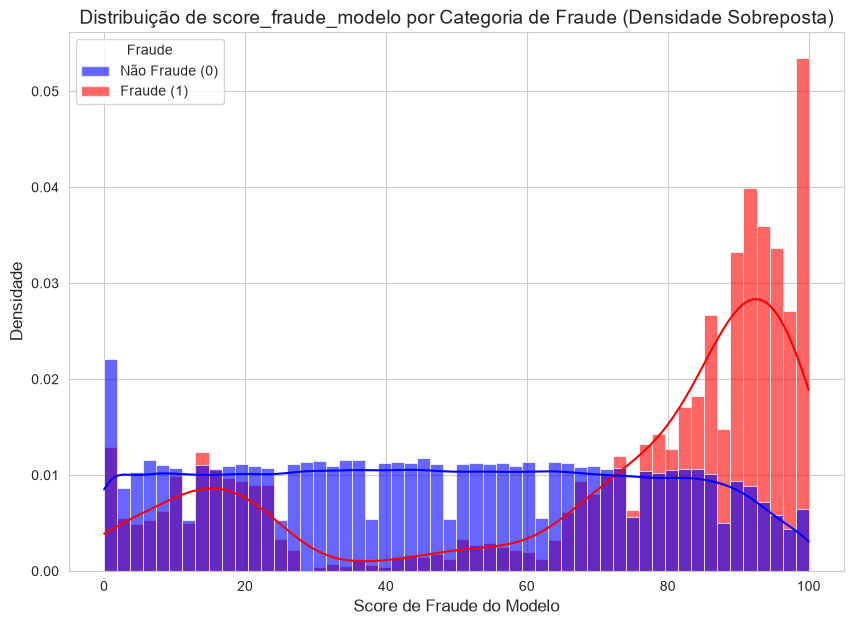

In [5]:
# célula #3
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

sns.set_style("whitegrid")
custom_palette = {0: 'blue', 1: 'red'}

plt.figure(figsize=(10, 7))
sns.histplot(
    data=df_modelo_antigo,
    x='score_fraude_modelo',
    hue='fraude',
    stat='density',
    common_norm=False,
    kde=True,
    palette=custom_palette,
    alpha=0.6,
    linewidth=0.5
)

plt.title('Distribuição de score_fraude_modelo por Categoria de Fraude (Densidade Sobreposta)', fontsize=14)
plt.xlabel('Score de Fraude do Modelo', fontsize=12)
plt.ylabel('Densidade', fontsize=12)

# Não depende dos handles gerados automaticamente pelo Seaborn.
legend_handles = [
    Patch(facecolor='blue', alpha=0.6, label='Não Fraude (0)'),
    Patch(facecolor='red', alpha=0.6, label='Fraude (1)')
]
plt.legend(handles=legend_handles, title='Fraude')
plt.show()

In [6]:
# célula #4
import pandas as pd
import numpy as np

# region - codigo
# Initialize a list to store results for each threshold
thresholds_analysis_list = []

# Iterate through thresholds from 0 to 100, stepping by 5
for threshold in range(0, 101, 5):
    # Create masks for approved/reproved transactions based on the current threshold
    approved_mask = df_modelo_antigo['score_fraude_modelo'] <= threshold
    reproved_mask = ~approved_mask

    # Calculate counts and rates
    quantidade_transacoes_aprovadas = approved_mask.sum()
    total_transactions = len(df_modelo_antigo)
    taxa_global_aprovacao = quantidade_transacoes_aprovadas / total_transactions if total_transactions > 0 else 0

    approved_frauds_count = df_modelo_antigo[approved_mask & (df_modelo_antigo['fraude'] == 1)].shape[0]
    taxa_fraude_aprovadas = approved_frauds_count / quantidade_transacoes_aprovadas if quantidade_transacoes_aprovadas > 0 else 0

    # Calculate financial impacts
    # Ganho com aprovações legítimas: 10% do valor_compra para transações aprovadas e não-fraude (fraude=0)
    ganho_legitimas_aprovadas = (df_modelo_antigo.loc[approved_mask & (df_modelo_antigo['fraude'] == 0), 'valor_compra'] * 0.10).sum()

    # Perda com fraudes aprovadas: 100% do valor_compra para transações aprovadas e fraude (fraude=1)
    perda_fraudes_aprovadas = (df_modelo_antigo.loc[approved_mask & (df_modelo_antigo['fraude'] == 1), 'valor_compra']).sum()

    # Ganho com fraudes reprovadas: 100% do valor_compra para transações reprovadas e fraude (fraude=1) (perda evitada)
    ganho_fraudes_reprovadas = (df_modelo_antigo.loc[reproved_mask & (df_modelo_antigo['fraude'] == 1), 'valor_compra']).sum()

    # Perda por transações legítimas reprovadas: 10% do valor_compra para transações reprovadas e não-fraude (fraude=0) (ganho perdido)
    perda_legitimas_reprovadas = (df_modelo_antigo.loc[reproved_mask & (df_modelo_antigo['fraude'] == 0), 'valor_compra'] * 0.10).sum()

    # Ganho líquido total
    ganho_liquido_total = ganho_legitimas_aprovadas - perda_fraudes_aprovadas + ganho_fraudes_reprovadas - perda_legitimas_reprovadas

    # Store all calculated metrics
    thresholds_analysis_list.append({
        'threshold': threshold,
        'quantidade_transacoes_aprovadas': quantidade_transacoes_aprovadas,
        'taxa_global_aprovacao': taxa_global_aprovacao,
        'taxa_fraude_aprovadas': taxa_fraude_aprovadas,
        'ganho_legitimas_aprovadas': ganho_legitimas_aprovadas,
        'perda_fraudes_aprovadas': perda_fraudes_aprovadas,
        'ganho_fraudes_reprovadas': ganho_fraudes_reprovadas,
        'perda_legitimas_reprovadas': perda_legitimas_reprovadas,
        'ganho_liquido_total': ganho_liquido_total
    })

# Convert the list of results to a DataFrame
df_threshold_analysis = pd.DataFrame(thresholds_analysis_list)

# Display the DataFrame
df_threshold_analysis

# endregion

,threshold,quantidade_transacoes_aprovadas,taxa_global_aprovacao,taxa_fraude_aprovadas,ganho_legitimas_aprovadas,perda_fraudes_aprovadas,ganho_fraudes_reprovadas,perda_legitimas_reprovadas,ganho_liquido_total
0,0,4969,0.033127,0.030388,17449.950,6610.25,540660.87,580669.950,-29169.380
1,5,11168,0.074453,0.029011,41349.454,16334.47,530936.65,556770.446,-818.812
2,10,18816,0.125440,0.029071,69064.839,33093.36,514177.76,529055.061,21094.178
3,15,26318,0.175453,0.035755,95511.022,53131.30,494139.82,502608.878,33910.664
4,20,33874,0.225827,0.037699,122195.362,69554.25,477716.87,475924.538,54433.444
5,25,41268,0.275120,0.038092,147606.648,89052.06,458219.06,450513.252,66260.396
6,30,48786,0.325240,0.032940,175810.554,94342.12,452929.00,422309.346,112088.088
7,35,56244,0.374960,0.028945,203456.168,95113.92,452157.20,394663.732,165835.716
8,40,63737,0.424913,0.026045,231460.698,96472.69,450798.43,366659.202,219127.236
9,45,71348,0.475653,0.023995,259088.602,98877.48,448393.64,339031.298,269573.464
